# Grouped K-fold vs the single 10% split

Issue [#47](https://github.com/adkipnis/mixedbench/issues/47).

MixedBench scores predictions for new rows of known groups and for new groups.<br>
Both use a seeded 10% split, but many datasets end up with tiny test sets (e.g. a single group or fewer than 10 rows).<br>
Results may then depend more on the seed than on the model.<br>
K-fold cross-validation would remedy this.

This experiment checks how well results reproduce across seeds under both schemes.

- **Models:** a generalized linear model (GLM) ignoring the groups, and a mixed model (lme4).
- **Score:** mean log predictive density on the test rows.
- **Δ:** the mixed model's score minus the GLM's.
- **K-fold:** 5 folds of rows or groups, or one fold per group for at most 5 groups.
- **Datasets:** all with up to 10,000 rows, except ordinal ones.
- **Seeds:** 10 per scheme.
- **Reproducibility ρ:** Spearman correlation of Δ across datasets between two seeds, averaged over all seed pairs.
- **Rule** ([fixed in advance](https://github.com/adkipnis/mixedbench/issues/47#issuecomment-6264978972)): keep the single split if ρ ≥ 0.9, else switch to K-fold if it at least halves 1 − ρ.

The fits took 10 hours on one 32-core node (`run.sbatch`); this notebook only reads their `scores.parquet`.

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

scores = pd.read_parquet('scores.parquet')
print(f'{scores["id"].nunique()} problems, {len(scores)} splits')
scores.groupby(['regime', 'scheme'])[['failed', 'singular', 'warned']].sum()

528 problems, 20920 splits


failed  singular  warned
regime scheme                          
groups kfold       17      3835     433
       single       2       785      67
rows   kfold        8      4025     307
       single       0       790      39

Failed fits leave Δ missing, so only datasets with all fits complete are compared.

In [2]:
def complete(regime: str) -> pd.DataFrame:
    """Returns the regime's Δ per problem (rows) by scheme and seed (columns), problems with every fit."""
    rows = scores[scores['regime'] == regime]
    table = rows.pivot_table(index='id', columns=['scheme', 'seed'], values='delta', dropna=False)
    return table.dropna()


def reliability(deltas: pd.DataFrame) -> float:
    """Returns the Spearman correlation of Δ across problems between two seeds, averaged over pairs."""
    correlations = [
        deltas[a].rank().corr(deltas[b].rank()) for a, b in combinations(deltas.columns, 2)
    ]
    return float(np.mean(correlations))


def decide(single: float, kfold: float) -> str:
    if single >= 0.9:
        return 'single split'
    if 1 - kfold <= (1 - single) / 2:
        return 'K-fold'
    return 'single split, noise reported'


records = []
for regime in ('rows', 'groups'):
    deltas = complete(regime)
    single = reliability(deltas['single'])
    kfold = reliability(deltas['kfold'])
    dropped = scores.loc[scores['regime'] == regime, 'id'].nunique() - len(deltas)
    records.append(
        {
            'regime': regime,
            'problems': len(deltas),
            'dropped': dropped,
            'rho_single': round(single, 3),
            'rho_kfold': round(kfold, 3),
            'noise_single': round(1 - single, 3),
            'noise_kfold': round(1 - kfold, 3),
            'decision': decide(single, kfold),
        }
    )
pd.DataFrame(records).set_index('regime')

,problems,dropped,rho_single,rho_kfold,noise_single,noise_kfold,decision
regime,,,,,,,
rows,525,3,0.589,0.89,0.411,0.11,K-fold
groups,514,4,0.439,0.87,0.561,0.13,K-fold


## Seed noise

Per dataset, the standard deviation (SD) of Δ across seeds, against the size of the single split's test set.<br>
With at most 5 groups, K-fold does not depend on the seed (SD = 0, drawn at the bottom edge).

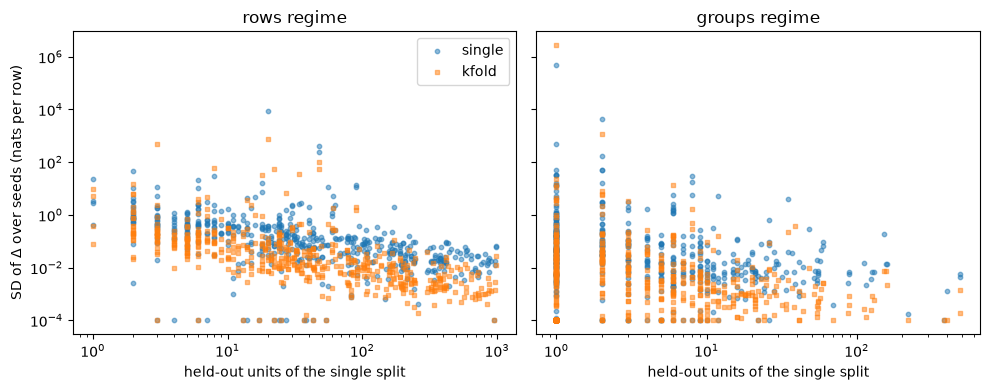

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, regime in zip(axes, ('rows', 'groups')):
    rows = scores[scores['regime'] == regime]
    spread = rows.pivot_table(index='id', columns='scheme', values='delta', aggfunc='std')
    units = rows[rows['scheme'] == 'single'].groupby('id')['units'].first()
    floor = 1e-4  # a zero SD drawn at the floor of the log axis
    for scheme, marker in (('single', 'o'), ('kfold', 's')):
        ax.scatter(
            units,
            spread[scheme].clip(lower=floor).loc[units.index],
            s=10,
            marker=marker,
            alpha=0.5,
            label=scheme,
        )
    ax.set(
        xscale='log',
        yscale='log',
        title=f'{regime} regime',
        xlabel='held-out units of the single split',
    )
axes[0].set_ylabel('SD of Δ over seeds (nats per row)')
axes[0].legend()
fig.tight_layout()
fig.savefig('seed-noise.pdf')

## Data noise

K-fold removes seed noise, not data noise: a dataset with four groups is still tested on four groups.<br>
Per dataset, the standard error (SE) of Δ across test groups against the number of groups G, and the median |Δ| / SE per range of G.

,problems,median |Δ| / SE
G,,
"(2.0, 5.0]",76,1.00
"(5.0, 10.0]",88,0.81
"(10.0, 30.0]",107,1.18
"(30.0, 100.0]",129,0.88
"(100.0, inf]",118,1.16


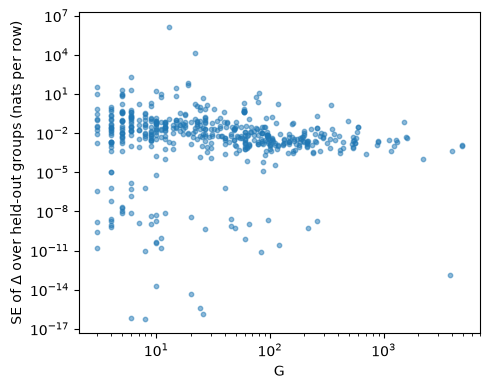

In [4]:
kfold = scores[
    (scores['regime'] == 'groups') & (scores['scheme'] == 'kfold') & (scores['seed'] == 0)
]
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(kfold['G'], kfold['delta_se'], s=10, alpha=0.5)
ax.set(xscale='log', yscale='log', xlabel='G', ylabel='SE of Δ over held-out groups (nats per row)')
fig.tight_layout()
fig.savefig('data-noise.pdf')
bins = pd.cut(kfold['G'], [2, 5, 10, 30, 100, np.inf])
ratio = (kfold['delta'].abs() / kfold['delta_se']).groupby(bins, observed=True)
pd.DataFrame({'problems': ratio.size(), 'median |Δ| / SE': ratio.median().round(2)})

## Cost

Total fitting time in seconds; K-fold fits each model once per fold.

In [5]:
fits = scores.groupby(['regime', 'scheme'])['seconds'].sum().unstack()
fits['ratio'] = (fits['kfold'] / fits['single']).round(1)
fits.round(0)

scheme,kfold,single,ratio
regime,,,
groups,50494.0,11703.0,4.0
rows,57597.0,12412.0,5.0


## Decision

**K-fold replaces the single split for both new rows and new groups.**<br>
Under the single split, ρ is only 0.59 for new rows and 0.44 for new groups.<br>
K-fold raises it to 0.89 and 0.87, more than halving the noise at 4–5 times the cost.<br>
Datasets with few groups stay, since |Δ| is about one SE regardless of G.<br>

The benchmark change is tracked in [#87](https://github.com/adkipnis/mixedbench/issues/87).